# Phân loại cảm xúc đánh giá phim 🎬

**Bài toán:** Cho một đoạn đánh giá phim, dự đoán người viết đang đánh giá **tích cực** (`positive`) hay **tiêu cực** (`negative`).

Ta sẽ đọc dữ liệu có sẵn, khám phá dữ liệu, làm sạch văn bản, huấn luyện mô hình và thử với câu do bạn nhập.

**Dữ liệu:** `IMDB-Dataset.csv`, gồm hai cột `review` (nội dung) và `sentiment` (nhãn). Các đánh giá trong file là **tiếng Anh**, vì vậy hãy nhập đánh giá tiếng Anh khi thử mô hình. Phần hướng dẫn được viết bằng tiếng Việt.

**Cách chạy:** Đặt notebook cùng thư mục với file CSV, chọn kernel Python 3, rồi chạy từng ô từ trên xuống (hoặc **Run All**). Không cần GPU, tải mô hình hay tài khoản dịch vụ. Ô cài thư viện cần Internet nếu máy chưa có thư viện.

Các bước: **CSV → khám phá → làm sạch → chia dữ liệu → TF-IDF → Logistic Regression → đánh giá → nhập thử**.

## 1. Chuẩn bị
Nếu máy chưa có thư viện, bỏ dấu # ở dòng %pip trong ô dưới và chạy ô đó một lần. Nếu đã cài, giữ nguyên và chạy tiếp. Nếu Jupyter yêu cầu khởi động lại kernel sau khi cài, hãy khởi động lại rồi tiếp tục từ ô import.

In [1]:
# Chỉ cần cài một lần nếu môi trường chưa có các thư viện này:
# %pip install pandas matplotlib scikit-learn

In [2]:
from pathlib import Path
import html

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.figsize"] = (8, 4)
RANDOM_STATE = 42  # Giữ cố định để dễ so sánh các lần thử.

## 2. Đọc file CSV
`pd.read_csv()` đưa dữ liệu vào một bảng (DataFrame). Nếu file ở nơi khác, sửa `CSV_PATH` thành đường dẫn của bạn.

Trước khi học, cần biết có bao nhiêu dòng, các cột là gì, có ô trống hoặc nhãn lạ không.

In [3]:
CSV_PATH = Path("IMDB-Dataset.csv")
if not CSV_PATH.is_file():
    raise FileNotFoundError("Không thấy IMDB-Dataset.csv. Hãy đặt file cạnh notebook hoặc sửa CSV_PATH.")

df = pd.read_csv(CSV_PATH)
if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("CSV cần có hai cột: review và sentiment.")

print(f"Số dòng: {len(df):,} | Số cột: {len(df.columns)}")
display(df.head(3))
display(df.isna().sum().rename("Số ô trống").to_frame())
display(df["sentiment"].value_counts(dropna=False).rename("Số đánh giá").to_frame())
print("Số nội dung review bị lặp:", df["review"].duplicated().sum())

Số dòng: 50,000 | Số cột: 2
Số nội dung review bị lặp: 418


,review,sentiment
0,One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked....,positive
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-ti...,positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air...",positive


,Số ô trống
review,0
sentiment,0


,Số đánh giá
sentiment,
positive,25000
negative,25000


## 3. Làm sạch dữ liệu
Đánh giá có thể chứa thẻ HTML như `<br />`, ký tự HTML như `&amp;`, khoảng trắng thừa và các cách viết hoa khác nhau. Ta chuẩn hóa chúng, giữ lại chữ cái tiếng Anh, chữ số và dấu nháy đơn.

Ta **giữ các từ phủ định** như `not`, `no`, `never`: bỏ chúng có thể làm đổi nghĩa câu. Bản gốc vẫn nằm trong `review`; bản dùng để học nằm trong `review_clean`.

Các dòng trống hoặc nhãn ngoài `positive`/`negative` sẽ bị loại. Sau làm sạch, nếu cùng nội dung có hai nhãn trái ngược thì bỏ nội dung đó; các nội dung lặp còn lại chỉ giữ một dòng. Làm việc này **trước khi chia dữ liệu** giúp tránh một bài đánh giá xuất hiện ở cả tập học và tập kiểm tra.

In [4]:
so_dong_ban_dau = len(df)
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

df["review_clean"] = (
    df["review"].astype(str)
    .map(html.unescape)
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.lower()
    .str.replace(r"[^a-z0-9'\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df = df[df["review_clean"].ne("")].copy()

so_nhan_moi_noi_dung = df.groupby("review_clean")["sentiment"].transform("nunique")
print("Số dòng có nội dung bị gán nhãn mâu thuẫn:", int(so_nhan_moi_noi_dung.gt(1).sum()))
df = df[so_nhan_moi_noi_dung.eq(1)].copy()
df = df.drop_duplicates(subset="review_clean").reset_index(drop=True)

if df["sentiment"].value_counts().reindex(["negative", "positive"], fill_value=0).min() < 5:
    raise ValueError("Cần ít nhất 5 đánh giá hợp lệ cho mỗi nhãn để tiếp tục bài học.")

print(f"Còn {len(df):,} đánh giá; đã loại {so_dong_ban_dau - len(df):,} dòng.")
display(df[["review", "review_clean", "sentiment"]].head(3))

Số dòng có nội dung bị gán nhãn mâu thuẫn: 0
Còn 49,577 đánh giá; đã loại 423 dòng.


,review,review_clean,sentiment
0,One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked....,one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked ...,positive
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-ti...,a wonderful little production the filming technique is very unassuming very old time bbc fashion...,positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air...",i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air ...,positive


## 4. Khám phá bằng biểu đồ
Biểu đồ trái cho biết hai nhãn có cân bằng không. Biểu đồ phải cho thấy phân bố độ dài đánh giá sau làm sạch.

**Thử quan sát:** Đánh giá dài hơn có đồng nghĩa với tích cực hơn không? Chỉ nhìn độ dài có đủ để phân loại không?

,count,mean,median,max
sentiment,,,,
negative,24696,229.4,174.0,1522
positive,24881,233.1,173.0,2473


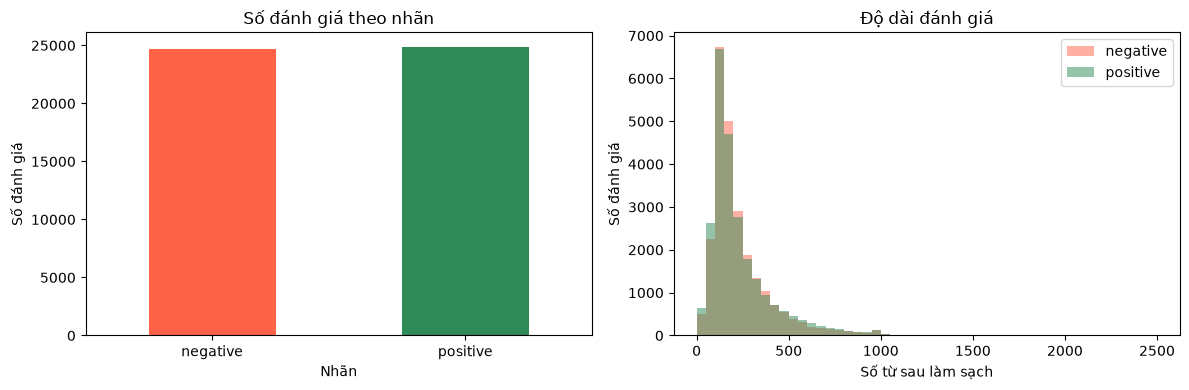

In [5]:
df["word_count"] = df["review_clean"].str.split().str.len()
display(df.groupby("sentiment")["word_count"].agg(["count", "mean", "median", "max"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["sentiment"].value_counts().reindex(["negative", "positive"]).plot.bar(
    ax=axes[0], color=["tomato", "seagreen"], rot=0
)
axes[0].set(title="Số đánh giá theo nhãn", xlabel="Nhãn", ylabel="Số đánh giá")

# Dùng chung khoảng chia để so sánh hai nhóm một cách nhất quán.
bins = range(0, int(df["word_count"].max()) + 51, 50)
df.loc[df["sentiment"].eq("negative"), "word_count"].plot.hist(
    ax=axes[1], bins=bins, alpha=0.5, color="tomato", label="negative"
)
df.loc[df["sentiment"].eq("positive"), "word_count"].plot.hist(
    ax=axes[1], bins=bins, alpha=0.5, color="seagreen", label="positive"
)
axes[1].set(title="Độ dài đánh giá", xlabel="Số từ sau làm sạch", ylabel="Số đánh giá")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Chia tập huấn luyện và kiểm tra
Giữ **80%** để mô hình học và **20%** để kiểm tra trên dữ liệu chưa được học. `stratify` giữ tỉ lệ hai nhãn gần giống nhau ở hai tập.

Mô hình chỉ nhận **nội dung đánh giá**, không nhận nhãn hay cột số từ làm đầu vào. Giữ nguyên tập kiểm tra khi so sánh các lần thử.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review_clean"],
    df["sentiment"],
    test_size=0.2,
    stratify=df["sentiment"],
    random_state=RANDOM_STATE,
)

print(f"Tập học: {len(X_train):,} đánh giá")
print(f"Tập kiểm tra: {len(X_test):,} đánh giá")
display(pd.DataFrame({
    "Tập học": y_train.value_counts(),
    "Tập kiểm tra": y_test.value_counts(),
}))

Tập học: 39,661 đánh giá
Tập kiểm tra: 9,916 đánh giá


,Tập học,Tập kiểm tra
sentiment,,
positive,19904,4977
negative,19757,4939


## 6. Biến văn bản thành số với TF-IDF
Máy học cần các con số. TF-IDF tạo một cột cho mỗi từ/cụm từ trong từ vựng, với trọng số phản ánh mức nổi bật của nó trong từng đánh giá.

- `ngram_range=(1, 2)`: xét từ đơn và cụm hai từ, ví dụ `good` và `not good`.
- `max_features=20000`: giới hạn số đặc trưng để việc học nhẹ hơn.
- `min_df=2`: chỉ xét từ/cụm từ có trong ít nhất hai đánh giá thuộc tập học.

**Tránh rò rỉ dữ liệu:** chỉ gọi `fit_transform` trên tập học. Tập kiểm tra dùng `transform`, tức sử dụng đúng từ vựng và trọng số đã học. Không chuyển ma trận lớn sang dạng đặc để tiết kiệm bộ nhớ.

In [7]:
# Bạn có thể sửa hai dòng cấu hình này rồi chạy lại từ đây xuống.
MAX_FEATURES = 20000
NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES,
    ngram_range=NGRAM_RANGE,
    min_df=2,
    sublinear_tf=True,
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Ma trận tập học (số đánh giá, số đặc trưng):", X_train_tfidf.shape)
print("Ma trận tập kiểm tra:", X_test_tfidf.shape)
print("Một số đặc trưng:", vectorizer.get_feature_names_out()[:20])

Ma trận tập học (số đánh giá, số đặc trưng): (39661, 20000)
Ma trận tập kiểm tra: (9916, 20000)
Một số đặc trưng: ['00' '000' '10' '10 10' '10 and' '10 because' '10 but' '10 for' '10 it'
 '10 minutes' '10 out' '10 stars' '10 the' '10 year' '10 years' '100'
 '1000' '101' '11' '12']


## 7. Huấn luyện Logistic Regression
Logistic Regression học trọng số cho các đặc trưng TF-IDF để phân biệt hai nhãn. Đây là lựa chọn gọn, chạy trên CPU và cho phép ta quan sát những từ/cụm từ có ảnh hưởng đến kết quả.

`C` điều chỉnh mức phạt trọng số lớn: giá trị nhỏ hơn khiến mô hình bị ràng buộc mạnh hơn. Bắt đầu với `C=1.0` để có mốc so sánh.

In [8]:
model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_tfidf, y_train)
print("Đã huấn luyện xong!")

Đã huấn luyện xong!


## 8. Kiểm tra mô hình học được gì
**Accuracy** là tỉ lệ dự đoán đúng. Báo cáo còn có:

- **Precision:** Trong các mẫu được dự đoán vào một nhãn, bao nhiêu mẫu đúng?
- **Recall:** Trong các mẫu thực sự thuộc một nhãn, mô hình tìm đúng bao nhiêu?
- **F1-score:** Điểm kết hợp precision và recall; cao hơn thường tốt hơn.
- **Support:** Số mẫu thật của mỗi nhãn trong tập kiểm tra.

Trong ma trận nhầm lẫn, **hàng là nhãn thật, cột là nhãn dự đoán**. Các ô trên đường chéo là dự đoán đúng.

Accuracy trên tập kiểm tra: 90.59%
              precision    recall  f1-score   support

    negative      0.918     0.891     0.904      4939
    positive      0.895     0.921     0.908      4977

    accuracy                          0.906      9916
   macro avg      0.906     0.906     0.906      9916
weighted avg      0.906     0.906     0.906      9916



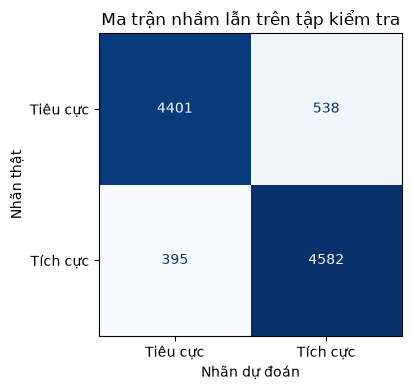

In [9]:
y_pred = model.predict(X_test_tfidf)
print(f"Accuracy trên tập kiểm tra: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["negative", "positive"],
    display_labels=["Tiêu cực", "Tích cực"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Ma trận nhầm lẫn trên tập kiểm tra")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thật")
plt.tight_layout()
plt.show()

### Đọc một vài trường hợp dự đoán sai
Điểm số không nói hết mọi điều. Hãy đọc các dòng bên dưới và tìm nguyên nhân: câu có mỉa mai không, có vừa khen vừa chê không, hay nhãn gốc có thể gây tranh luận?

Thay `.head(5)` bằng `.sample(5, random_state=42)` nếu muốn xem các lỗi ngẫu nhiên khi có đủ ít nhất 5 lỗi. Để đọc toàn bộ một dòng, dùng `print(loi.iloc[0]["review"])` khi bảng lỗi không rỗng.

In [10]:
ket_qua = df.loc[X_test.index, ["review", "sentiment"]].copy()
ket_qua["du_doan"] = y_pred
loi = ket_qua[ket_qua["sentiment"].ne(ket_qua["du_doan"])]
print(f"Có {len(loi):,} dự đoán sai trong {len(ket_qua):,} đánh giá kiểm tra.")
display(loi.head(5))

Có 933 dự đoán sai trong 9,916 đánh giá kiểm tra.


,review,sentiment,du_doan
651,I think that you can not imagine how these people really work...!! Before I came to the studios ...,negative,positive
36535,Tiny Tweet and Sly the sneak are locked up in cages for a train ride to who knows where. Swingin...,positive,negative
14394,"I'm not here to tell you ""Armored"" is Kubrickian, Hitchcockian or Fellini-esquire. Nope. Referen...",positive,negative
12423,"this movie probably had a $750 budget, and still managed to surpass Titanic. i rented this the d...",positive,negative
30009,I was really disappointed with this film. The first Waters movie I saw was Serial Mom and I love...,negative,positive


## 9. Nhìn vào các từ/cụm từ mô hình đã học
Trong bài toán hai lớp này, trọng số dương hướng về `model.classes_[1]`, trọng số âm hướng về `model.classes_[0]`. Với hai nhãn đang dùng, đó lần lượt là `positive` và `negative`.

Các từ dưới đây chỉ phản ánh **mối liên hệ trong tập huấn luyện**. Chúng không phải danh sách từ luôn tích cực hoặc luôn tiêu cực; một câu còn phụ thuộc nhiều đặc trưng cùng lúc.

Thứ tự lớp: ['negative' 'positive']


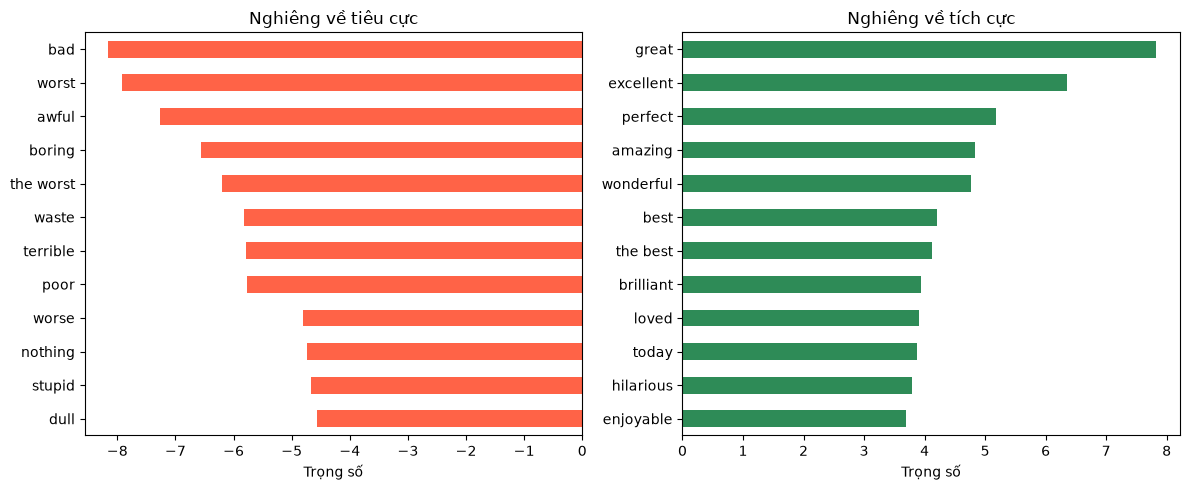

In [11]:
print("Thứ tự lớp:", model.classes_)
trong_so = pd.Series(model.coef_[0], index=vectorizer.get_feature_names_out())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
trong_so.nsmallest(12).sort_values(ascending=False).plot.barh(ax=axes[0], color="tomato")
axes[0].set(title="Nghiêng về tiêu cực", xlabel="Trọng số")
trong_so.nlargest(12).sort_values().plot.barh(ax=axes[1], color="seagreen")
axes[1].set(title="Nghiêng về tích cực", xlabel="Trọng số")
plt.tight_layout()
plt.show()

## 10. Nhập đánh giá của bạn
**Sửa chuỗi `danh_gia_moi` rồi chạy lại ô dưới.** Không cần huấn luyện lại cho mỗi câu mới.

Ta áp dụng đúng các bước làm sạch và từ vựng đã dùng khi học. Không gọi lại `fit` với câu mới.

Phần trăm hiển thị là **xác suất do mô hình ước lượng**, không phải cam kết rằng kết quả đúng với xác suất đó. Mô hình có thể sai với câu mỉa mai, câu pha trộn khen/chê hoặc nội dung khác dữ liệu IMDb. Nếu toàn bộ từ nằm ngoài từ vựng, ta sẽ yêu cầu câu khác thay vì đưa ra kết quả từ một đầu vào không có đặc trưng.

In [12]:
danh_gia_moi = "The movie was wonderful. I loved the story and the acting!"

van_ban_moi = (
    pd.Series([danh_gia_moi])
    .map(html.unescape)
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.lower()
    .str.replace(r"[^a-z0-9'\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
X_moi = vectorizer.transform(van_ban_moi)

if van_ban_moi.iloc[0] == "":
    print("Hãy nhập một đánh giá tiếng Anh có nội dung.")
elif X_moi.nnz == 0:
    print("Không có từ nào thuộc từ vựng đã học. Hãy thử một đánh giá tiếng Anh khác.")
else:
    nhan_moi = model.predict(X_moi)[0]
    xac_suat = model.predict_proba(X_moi)[0]
    ten_nhan = {"negative": "TIÊU CỰC", "positive": "TÍCH CỰC"}

    print("Đánh giá:", danh_gia_moi)
    print("Kết quả:", ten_nhan[nhan_moi])
    display(pd.DataFrame({
        "Nhãn": [ten_nhan[nhan] for nhan in model.classes_],
        "Xác suất mô hình ước lượng": [f"{p:.1%}" for p in xac_suat],
    }))

Đánh giá: The movie was wonderful. I loved the story and the acting!
Kết quả: TÍCH CỰC


,Nhãn,Xác suất mô hình ước lượng
0,TIÊU CỰC,9.1%
1,TÍCH CỰC,90.9%


## 11. Tự khám phá tiếp
Thử thay câu ở bước 10 và ghi lại điều bạn quan sát được:

1. `The movie was good.` và `The movie was not good.` — thêm phủ định có làm đổi kết quả không?
2. `The acting was great, but the story was boring.` — mô hình phản ứng thế nào khi vừa khen vừa chê?
3. `Great, another two hours of my life wasted.` — mô hình có nhận ra mỉa mai không?

Tiếp theo, đổi `NGRAM_RANGE` từ `(1, 2)` thành `(1, 1)`, hoặc `MAX_FEATURES` từ `20000` thành `10000`. Chỉ đổi **một yếu tố mỗi lần**, rồi chạy lại từ bước 6 đến hết. So sánh điểm số, các trường hợp sai và cách mô hình xử lý phủ định. Bạn cũng có thể thử `C=0.5` hoặc `C=2.0` ở bước 7.

**Giới hạn cần nhớ:** Chia ngẫu nhiên giúp đo hiệu quả trên phần dữ liệu IMDb được giữ lại, chưa bảo đảm hiệu quả tương tự trên đánh giá ở nguồn khác. Dữ liệu trùng hoàn toàn đã được loại sau chuẩn hóa; các bản gần giống vẫn có thể tồn tại. Nếu bạn thử nhiều cấu hình rồi chọn cấu hình tốt nhất dựa trên tập kiểm tra, điểm số đó dần trở nên thiên lệch. Khi phát triển nghiêm túc, hãy thêm tập validation để chọn cấu hình và giữ riêng tập test đến lần đánh giá cuối.

Muốn phân loại tiếng Việt, hãy dùng dữ liệu đánh giá phim tiếng Việt có nhãn, điều chỉnh bước làm sạch để giữ chữ có dấu, rồi huấn luyện và đánh giá lại.
